## Practice: Basic Artificial Neural Networks
Credits: this notebook belongs to [Practical DL](https://docs.google.com/forms/d/e/1FAIpQLScvrVtuwrHSlxWqHnLt1V-_7h2eON_mlRR6MUb3xEe5x9LuoA/viewform?usp=sf_link) course by Yandex School of Data Analysis.

We will start working with neural networks on the practice session. Your homework will be to finish the implementation of the layers.

Our goal is simple, yet an actual implementation may take some time :). We are going to write an Artificial Neural Network (almost) from scratch. The software design was heavily inspired by [PyTorch](http://pytorch.org) which is the main framework of our course 

Speaking about the homework (once again, it will be really similar to this seminar), it requires sending **multiple** files, please do not forget to include all the files when sending to TA. The list of files:
- This notebook
- modules.ipynb with all blocks implemented (except maybe `Conv2d` and `MaxPool2d` layers implementation which are part of 'advanced' version of this homework)

In [1]:
%matplotlib inline
from time import time, sleep
import numpy as np
import matplotlib.pyplot as plt
from IPython import display

# Framework

Implement everything in `modules.ipynb`. Read all the comments thoughtfully to ease the pain. Please try not to change the prototypes.

Do not forget, that each module should return **AND** store `output` and `gradInput`.

The typical assumption is that `module.backward` is always executed after `module.forward`,
so `output` is stored, this would be useful for `SoftMax`. 

### Tech note
Prefer using `np.multiply`, `np.add`, `np.divide`, `np.subtract` instead of `*`,`+`,`/`,`-` for better memory handling.

Example: suppose you allocated a variable 

```
a = np.zeros(...)
```
So, instead of
```
a = b + c  # will be reallocated, GC needed to free
``` 
You can use: 
```
np.add(b,c,out = a) # puts result in `a`
```

In [2]:
# (re-)load layers
%run modules.ipynb

# Toy example

Use this example to debug your code, start with logistic regression and then test other layers. You do not need to change anything here. This code is provided for you to test the layers. Also it is easy to use this code in MNIST task.

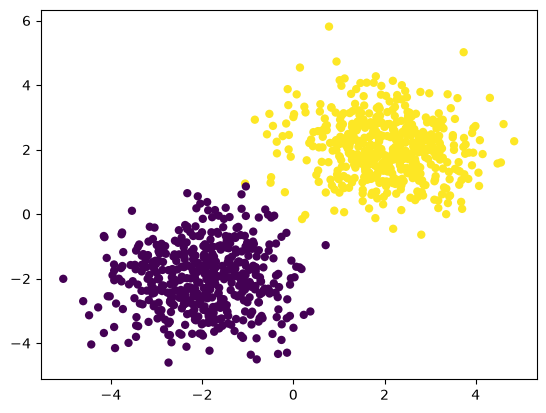

In [3]:
# Generate some data
N = 500

X1 = np.random.randn(N,2) + np.array([2,2])
X2 = np.random.randn(N,2) + np.array([-2,-2])

Y = np.concatenate([np.ones(N),np.zeros(N)])[:,None]
Y = np.hstack([Y, 1-Y])

X = np.vstack([X1,X2])
plt.scatter(X[:,0],X[:,1], c = Y[:,0], edgecolors= 'none')

Define a **logistic regression** for debugging. 

In [4]:
net = Sequential()
net.add(Linear(2, 2))
net.add(LogSoftMax())

criterion = ClassNLLCriterion()

print(net)

# Test something like that then 

# net = Sequential()
# net.add(Linear(2, 4))
# net.add(ReLU())
# net.add(Linear(4, 2))
# net.add(LogSoftMax())

Linear 2 -> 2
LogSoftMax



Start with batch_size = 1000 to make sure every step lowers the loss, then try stochastic version.

In [5]:
# Iptimizer params
optimizer_config = {'learning_rate' : 1e-1, 'momentum': 0.9}
optimizer_state = {}

# Looping params
n_epoch = 20
batch_size = 128

In [6]:
# batch generator
def get_batches(dataset, batch_size):
    X, Y = dataset
    n_samples = X.shape[0]
        
    # Shuffle at the start of epoch
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    
    for start in range(0, n_samples, batch_size):
        end = min(start + batch_size, n_samples)
        
        batch_idx = indices[start:end]
    
        yield X[batch_idx], Y[batch_idx]

### Train

Basic training loop. Examine it.

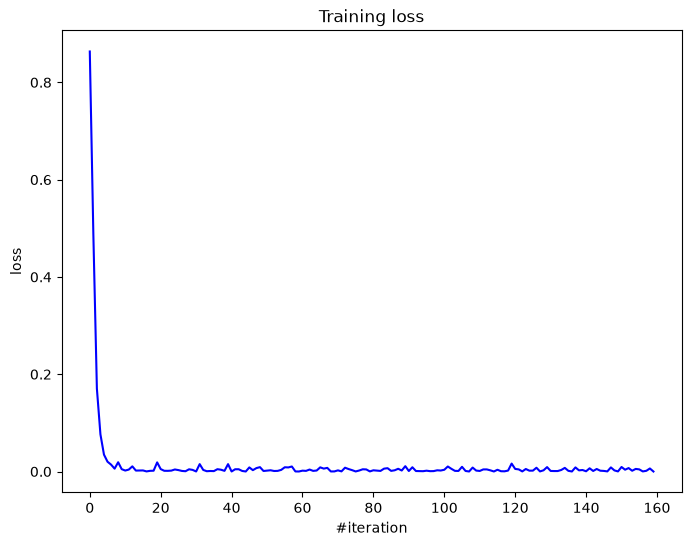

Current loss: 0.000010


In [7]:
loss_history = []

for i in range(n_epoch):
    for x_batch, y_batch in get_batches((X, Y), batch_size):
        
        net.zeroGradParameters()
        
        # Forward
        predictions = net.forward(x_batch)
        loss = criterion.forward(predictions, y_batch)
    
        # Backward
        dp = criterion.backward(predictions, y_batch)
        net.backward(x_batch, dp)
        
        # Update weights
        sgd_momentum(net.getParameters(), 
                     net.getGradParameters(), 
                     optimizer_config,
                     optimizer_state)      
        
        loss_history.append(loss)

    # Visualize
    display.clear_output(wait=True)
    plt.figure(figsize=(8, 6))
        
    plt.title("Training loss")
    plt.xlabel("#iteration")
    plt.ylabel("loss")
    plt.plot(loss_history, 'b')
    plt.show()
    
    print('Current loss: %f' % loss)    

# Digit classification 

We are using old good [MNIST](http://yann.lecun.com/exdb/mnist/) as our dataset. It can be downloaded with the following file.

In [8]:
# yann.lecun.com не отдаёт файлы (404), mnist.py их не скачает,
# поэтому архивы .gz скачиваются с зеркала, которое использует torchvision
import os
from urllib.request import urlretrieve

for name in ['train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz',
             't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz']:
    if not os.path.exists(name):
        urlretrieve('https://ossci-datasets.s3.amazonaws.com/mnist/' + name, name)

In [9]:
import mnist
X_train, y_train, X_val, y_val, X_test, y_test = mnist.load_dataset()

One-hot encode the labels first.

In [10]:
def one_hot(y, n_classes=10):
    res = np.zeros((len(y), n_classes))
    res[np.arange(len(y)), y] = 1
    return res

# картинки 28x28 преобразуются в векторы для Linear
X_train = X_train.reshape(len(X_train), -1)
X_val = X_val.reshape(len(X_val), -1)
X_test = X_test.reshape(len(X_test), -1)

y_train_oh, y_val_oh, y_test_oh = one_hot(y_train), one_hot(y_val), one_hot(y_test)
print(X_train.shape, y_train_oh.shape, X_val.shape, X_test.shape)

(50000, 784) (50000, 10) (10000, 784) (10000, 784)


- **Compare** `ReLU`, `ELU`, `LeakyReLU`, `SoftPlus` activation functions. 
You would better pick the best optimizer params for each of them, but it is overkill for now. Use an architecture of your choice for the comparison.
- **Try** inserting `BatchNormalization` (folowed by `ChannelwiseScaling`) between `Linear` module and activation functions.
- Plot the losses both from activation functions comparison and `BatchNormalization` comparison on one plot. Please find a scale (log?) when the lines are distinguishable, do not forget about naming the axes, the plot should be goodlooking.
- Plot the losses for two networks: one trained by momentum_sgd, another one trained by Adam. Which one performs better?
- Hint: good logloss for MNIST should be around 0.5. 

In [11]:
def make_net(activation, bn=False, hidden=128):
    net = Sequential()
    net.add(Linear(784, hidden))
    if bn:
        net.add(BatchNormalization(alpha=0.9))
        net.add(ChannelwiseScaling(hidden))
    net.add(activation())
    net.add(Linear(hidden, 10))
    net.add(LogSoftMax())
    return net


def train(net, optimizer, config, n_epoch=5, batch_size=128, X=X_train, Y=y_train_oh):
    criterion = ClassNLLCriterion()
    state = {}
    history = []
    net.train()
    start = time()
    for epoch in range(n_epoch):
        for x_batch, y_batch in get_batches((X, Y), batch_size):
            net.zeroGradParameters()
            pred = net.forward(x_batch)
            history.append(criterion.forward(pred, y_batch))
            net.backward(x_batch, criterion.backward(pred, y_batch))
            optimizer(net.getParameters(), net.getGradParameters(), config, state)
    return history, time() - start


def accuracy(net, X, y):
    net.evaluate()
    pred = net.forward(X).argmax(axis=1)
    net.train()
    return np.mean(pred == y)


def smooth(x, k=50):
    # скользящее среднее, иначе лосс по батчам слишком шумный
    return np.convolve(x, np.ones(k) / k, mode='valid')


sgd_config = {'learning_rate': 1e-2, 'momentum': 0.9}
activations = [ReLU, ELU, LeakyReLU, SoftPlus]

results = {}
for bn in [False, True]:
    for act in activations:
        np.random.seed(42)
        net = make_net(act, bn=bn)
        name = act.__name__ + (' + BN' if bn else '')
        hist, t = train(net, sgd_momentum, sgd_config)
        results[name] = hist
        print('%-18s time %.1fs  val acc %.4f  last loss %.4f'
              % (name, t, accuracy(net, X_val, y_val), np.mean(hist[-50:])))

ReLU               time 8.1s  val acc 0.9491  last loss 0.2001


ELU                time 9.4s  val acc 0.9305  last loss 0.2602


LeakyReLU          time 8.7s  val acc 0.9478  last loss 0.2037


SoftPlus           time 10.4s  val acc 0.9247  last loss 0.2815


ReLU + BN          time 9.2s  val acc 0.9606  last loss 0.1547


ELU + BN           time 10.1s  val acc 0.9468  last loss 0.2000


LeakyReLU + BN     time 9.2s  val acc 0.9600  last loss 0.1584


SoftPlus + BN      time 10.3s  val acc 0.9465  last loss 0.2043


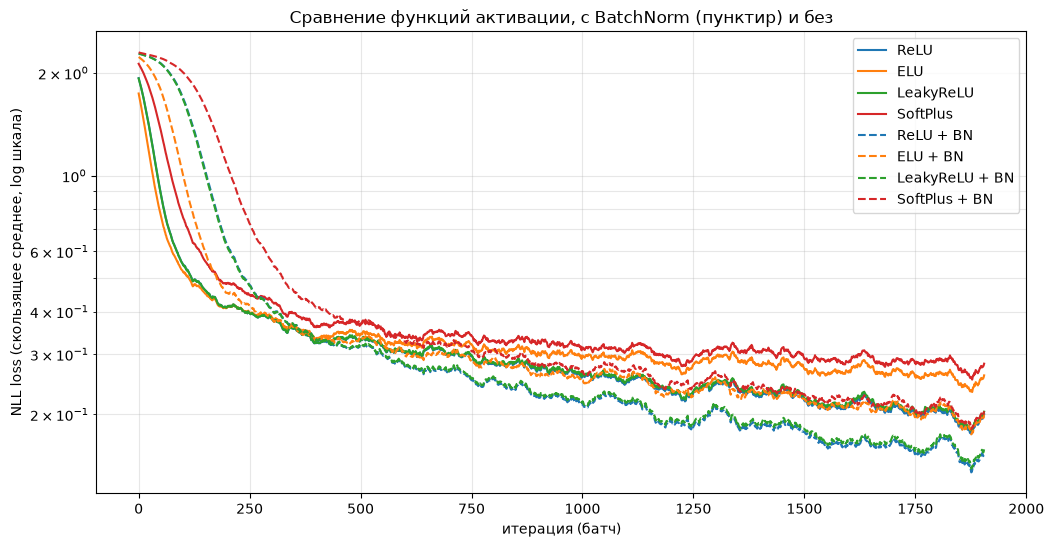

In [12]:
plt.figure(figsize=(12, 6))
colors = dict(zip(['ReLU', 'ELU', 'LeakyReLU', 'SoftPlus'], ['C0', 'C1', 'C2', 'C3']))
for name, hist in results.items():
    act = name.split()[0]
    plt.plot(smooth(hist), color=colors[act], linestyle='--' if 'BN' in name else '-', label=name)
plt.yscale('log')
plt.xlabel('итерация (батч)')
plt.ylabel('NLL loss (скользящее среднее, log шкала)')
plt.title('Сравнение функций активации, с BatchNorm (пунктир) и без')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

SGD momentum: val acc 0.9491, time 7.7s
Adam:         val acc 0.9668, time 9.9s


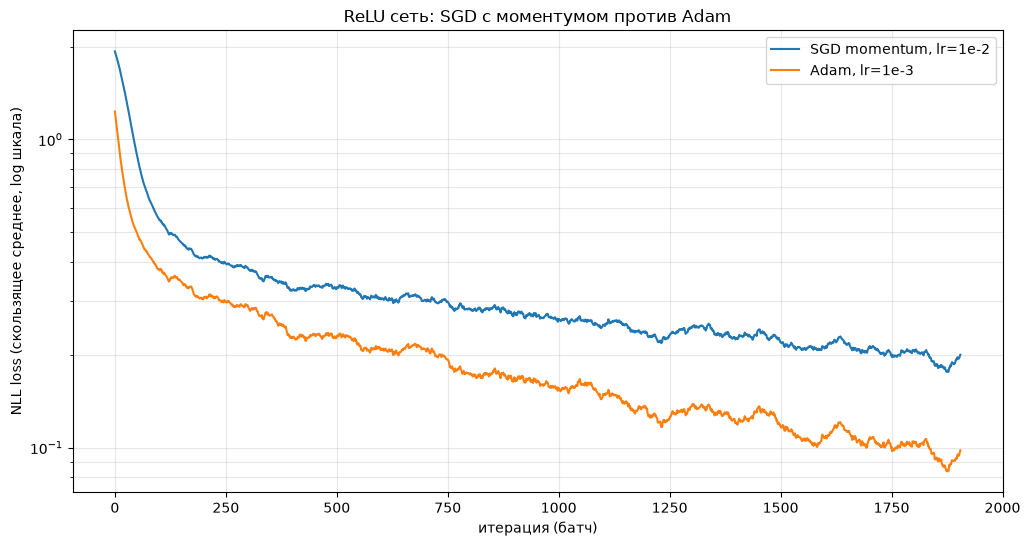

In [13]:
adam_config = {'learning_rate': 1e-3, 'beta1': 0.9, 'beta2': 0.999, 'epsilon': 1e-8}

np.random.seed(42)
net_sgd = make_net(ReLU)
hist_sgd, t_sgd = train(net_sgd, sgd_momentum, sgd_config)

np.random.seed(42)
net_adam = make_net(ReLU)
hist_adam, t_adam = train(net_adam, adam_optimizer, adam_config)

print('SGD momentum: val acc %.4f, time %.1fs' % (accuracy(net_sgd, X_val, y_val), t_sgd))
print('Adam:         val acc %.4f, time %.1fs' % (accuracy(net_adam, X_val, y_val), t_adam))

plt.figure(figsize=(12, 6))
plt.plot(smooth(hist_sgd), label='SGD momentum, lr=1e-2')
plt.plot(smooth(hist_adam), label='Adam, lr=1e-3')
plt.yscale('log')
plt.xlabel('итерация (батч)')
plt.ylabel('NLL loss (скользящее среднее, log шкала)')
plt.title('ReLU сеть: SGD с моментумом против Adam')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.show()

Adam (lr = 1e-3) сходится быстрее, чем SGD с моментумом (lr = 1e-2), на той же сети 784-128-10 с ReLU. Лосс у Adam всё время ниже, val acc 0.967 против 0.949. Итерация Adam немного дольше, так как он хранит два момента для каждого параметра.

Write your personal opinion on the activation functions, think about computation times too. Does `BatchNormalization` help?

Активации: сеть 784-128-10, SGD с моментумом, 5 эпох. Лучший результат у ReLU (0.949) и LeakyReLU (0.948), их кривые почти совпадают, потому что при slope = 0.03 LeakyReLU мало отличается от ReLU. ELU (0.931) и SoftPlus (0.925) за 5 эпох обучились хуже. ReLU ещё и самая быстрая: в ELU и SoftPlus в forward и backward считается экспонента. Поэтому по умолчанию разумно брать ReLU.

BatchNorm: со всеми активациями лосс в конце ниже, а val acc выше на 1-2% (ReLU 0.949 -> 0.961, SoftPlus 0.925 -> 0.947). На первых итерациях с BN лосс падает медленнее. Вероятная причина в том, что gamma в ChannelwiseScaling инициализируется маленькими числами. Эпоха с BN идёт немного дольше.

**Finally**, use all your knowledge to build a super cool model on this dataset. Use **dropout** to prevent overfitting, play with **learning rate decay**. You can use **data augmentation** such as rotations, translations to boost your score. Use your knowledge and imagination to train a model. Don't forget to call `training()` and `evaluate()` methods to set desired behaviour of `BatchNormalization` and `Dropout` layers.

Linear 784 -> 512
BatchNormalization
ChannelwiseScaling
ReLU
Dropout
Linear 512 -> 256
BatchNormalization
ChannelwiseScaling
ReLU
Dropout
Linear 256 -> 10
LogSoftMax



epoch  1  train loss 0.7422  val acc 0.9665


epoch  2  train loss 0.2089  val acc 0.9740


epoch  3  train loss 0.1692  val acc 0.9762


epoch  4  train loss 0.1489  val acc 0.9790


epoch  5  train loss 0.1347  val acc 0.9816


... (6 outputs left out)

epoch 12  train loss 0.0923  val acc 0.9872


epoch 13  train loss 0.0890  val acc 0.9868


epoch 14  train loss 0.0895  val acc 0.9876


epoch 15  train loss 0.0844  val acc 0.9874


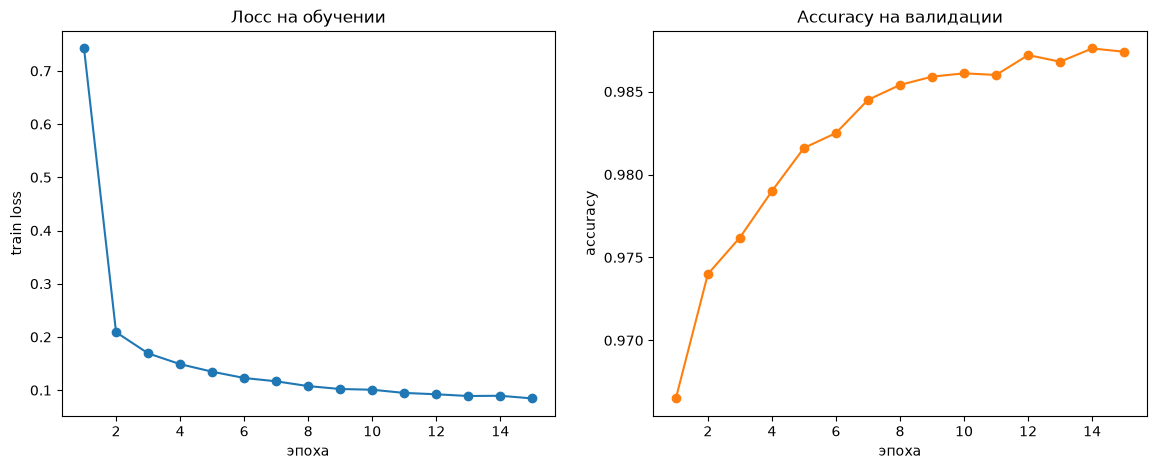

In [14]:
def augment(X, max_shift=2):
    # случайный сдвиг каждой картинки на -2..2 пикселя по осям
    imgs = X.reshape(-1, 28, 28)
    res = np.empty_like(imgs)
    dx = np.random.randint(-max_shift, max_shift + 1, len(imgs))
    dy = np.random.randint(-max_shift, max_shift + 1, len(imgs))
    for i in range(len(imgs)):
        res[i] = np.roll(imgs[i], (dy[i], dx[i]), axis=(0, 1))
    return res.reshape(len(X), -1)


def make_final_net():
    net = Sequential()
    net.add(Linear(784, 512))
    net.add(BatchNormalization(alpha=0.9))
    net.add(ChannelwiseScaling(512))
    net.add(ReLU())
    net.add(Dropout(0.3))
    net.add(Linear(512, 256))
    net.add(BatchNormalization(alpha=0.9))
    net.add(ChannelwiseScaling(256))
    net.add(ReLU())
    net.add(Dropout(0.3))
    net.add(Linear(256, 10))
    net.add(LogSoftMax())
    return net


np.random.seed(42)
final_net = make_final_net()
print(final_net)

criterion = ClassNLLCriterion()
config = {'learning_rate': 1e-3, 'beta1': 0.9, 'beta2': 0.999, 'epsilon': 1e-8}
state = {}
n_epoch = 15
lr_decay = 0.85

train_loss, val_acc = [], []
for epoch in range(n_epoch):
    final_net.train()
    epoch_loss = []
    for x_batch, y_batch in get_batches((X_train, y_train_oh), 128):
        x_batch = augment(x_batch)
        final_net.zeroGradParameters()
        pred = final_net.forward(x_batch)
        epoch_loss.append(criterion.forward(pred, y_batch))
        final_net.backward(x_batch, criterion.backward(pred, y_batch))
        adam_optimizer(final_net.getParameters(), final_net.getGradParameters(), config, state)
    config['learning_rate'] *= lr_decay

    train_loss.append(np.mean(epoch_loss))
    val_acc.append(accuracy(final_net, X_val, y_val))
    print('epoch %2d  train loss %.4f  val acc %.4f' % (epoch + 1, train_loss[-1], val_acc[-1]))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(range(1, n_epoch + 1), train_loss, marker='o')
ax[0].set_xlabel('эпоха')
ax[0].set_ylabel('train loss')
ax[0].set_title('Лосс на обучении')
ax[1].plot(range(1, n_epoch + 1), val_acc, marker='o', color='C1')
ax[1].set_xlabel('эпоха')
ax[1].set_ylabel('accuracy')
ax[1].set_title('Accuracy на валидации')
plt.show()

Print here your accuracy on test set. It should be around 90%.

In [15]:
test_acc = accuracy(final_net, X_test, y_test)
print('Test accuracy (numpy): %.4f' % test_acc)

Test accuracy (numpy): 0.9866


### Comparing with PyTorch implementation
The last (and maybe the easiest step after compared to the previous tasks: build a network with the same architecture as above now with PyTorch.

You can refer to the `week0_09` or `Lab3_part2` notebooks for hints.

__Good Luck!__

In [16]:
import torch
from torch import nn

torch.manual_seed(42)
np.random.seed(42)

torch_net = nn.Sequential(
    nn.Linear(784, 512),
    nn.BatchNorm1d(512, eps=1e-3, momentum=0.1),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 256),
    nn.BatchNorm1d(256, eps=1e-3, momentum=0.1),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 10),
    nn.LogSoftmax(dim=1),
)
opt = torch.optim.Adam(torch_net.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=lr_decay)
loss_fn = nn.NLLLoss()


def torch_accuracy(net, X, y):
    net.eval()
    with torch.no_grad():
        pred = net(torch.tensor(X, dtype=torch.float32)).argmax(dim=1).numpy()
    return np.mean(pred == y)


start = time()
for epoch in range(n_epoch):
    torch_net.train()
    for x_batch, y_batch in get_batches((X_train, y_train), 128):
        x_batch = torch.tensor(augment(x_batch), dtype=torch.float32)
        y_batch = torch.tensor(y_batch, dtype=torch.long)
        opt.zero_grad()
        loss = loss_fn(torch_net(x_batch), y_batch)
        loss.backward()
        opt.step()
    sched.step()
    print('epoch %2d  val acc %.4f' % (epoch + 1, torch_accuracy(torch_net, X_val, y_val)))

print('time %.1fs' % (time() - start))
print('Test accuracy (numpy):   %.4f' % test_acc)
print('Test accuracy (pytorch): %.4f' % torch_accuracy(torch_net, X_test, y_test))

epoch  1  val acc 0.9652


epoch  2  val acc 0.9727


epoch  3  val acc 0.9774


epoch  4  val acc 0.9803


epoch  5  val acc 0.9805


epoch  6  val acc 0.9833


... (5 outputs left out)

epoch 12  val acc 0.9864


epoch 13  val acc 0.9861


epoch 14  val acc 0.9862


epoch 15  val acc 0.9866
time 33.6s
Test accuracy (numpy):   0.9866
Test accuracy (pytorch): 0.9867


Та же сеть на PyTorch (те же слои, Adam, уменьшение lr, аугментация, 15 эпох) даёт на тесте 0.9867, сеть на numpy даёт 0.9866. Точности почти совпадают, значит слои на numpy написаны правильно. PyTorch работает быстрее.